# Structured word-Taylor Hamiltonian dynamics

Use two spins, $H=0.6Z_0Z_1+0.35(X_0+X_1)$, $t=1$, $\hbar=1$, input $|00\rangle$ and observable $Z_0$. The source prepares a degree register and three independent Hamiltonian-term registers. It selects only active slots and uncomputes every preparation. No list of $L^K$ words or dense evolution gate is constructed.

Matrix exponentiation and matrix Taylor recurrences are bounded classical checks. Conditional states are checked before final system readout; complete exports contain resets and measurements. Qiskit2.6.2 is Apache-2.0, SciPy1.18.1 is BSD-3-Clause, and the original implementation is MIT.

In [1]:
from pathlib import Path
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit
root = Path.cwd()
if not (root / "src/openquantum/simulation/word_taylor.py").is_file() and (root.parent / "src/openquantum/simulation/word_taylor.py").is_file():
    root = root.parent
if (root / "src/openquantum/simulation/word_taylor.py").is_file():
    sys.path.insert(0, str(root / "src"))
    from openquantum.simulation import word_taylor as wt
else:
    sys.path.insert(0, str(Path.cwd()))
    import word_taylor as wt
terms = [(0.6, "ZZ"), (0.35, "IX"), (0.35, "XI")]


## Actual access definitions

With $\alpha=\sum_j|c_j|$ and $\delta=t/r$, prepare degree probabilities $d_k=(\alpha|\delta|)^k/(k!s)$ and each term-register probability $p_j=|c_j|/\alpha$, where $s=\sum_{k=0}^K(\alpha|\delta|)^k/k!$. Degree $k$ activates the first $k$ signed Pauli slots. The other slots are independent and contribute total weight1 after uncomputation. The resulting zero-ancilla block is $T_K(-i\delta H)/s$.

The boxes below are actual circuit definitions whose bodies are lowered in the primitive exports.

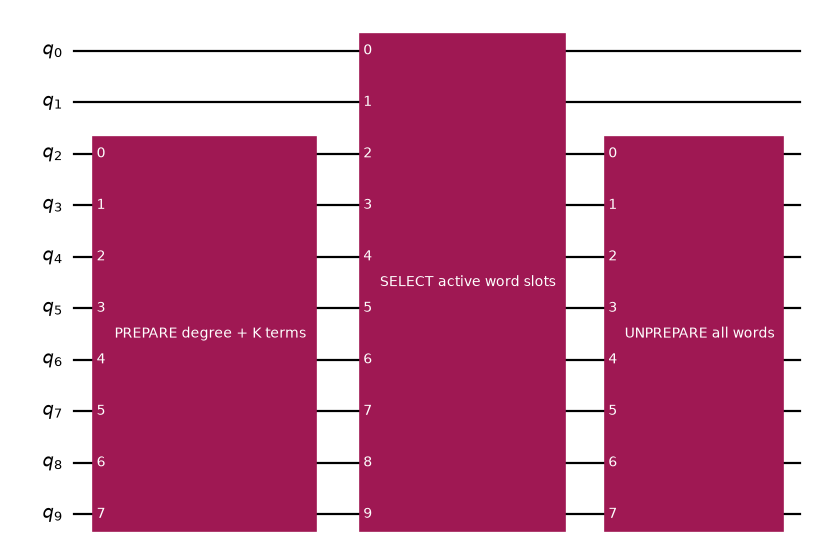

In [2]:
access = wt.build_word_taylor(terms, time=0.25, degree=3)
diagram = QuantumCircuit(access.circuit.num_qubits)
ancillas = list(range(access.n_system, diagram.num_qubits))
diagram.append(access.prepare.to_gate(label="PREPARE degree + K terms"), ancillas)
diagram.append(access.select.to_gate(label="SELECT active word slots"), range(diagram.num_qubits))
diagram.append(access.prepare.inverse().to_gate(label="UNPREPARE all words"), ancillas)
figure = diagram.draw(output="mpl", fold=-1, scale=0.8)
display(figure)
plt.close(figure)

## Native access, OAA and normalization2 padding

One OAA round has accepted block $3B-4BB^\dagger B$ for the actual source block $B$. An exact scaled-unitary sine formula does not establish this finite polynomial's success.

When native $s\le2$, an extra signal flag prepares zero with probability $s/2$. The signal0 branch controls actual word SELECT; signal1 applies Z to a sign qubit in $|+\rangle$, giving zero overlap. Uncompute all flags and words to encode $T_K/2$. One OAA round then gives $(3T_K-T_KT_K^\dagger T_K)/2$. These circuits use twelve total wires instead of the native ten. Every ancillary wire participates in postselection and reflection.

In [3]:
checks = []
cases = []
for steps in (1, 2, 4):
    access = wt.build_word_taylor(terms, time=1/steps, degree=3)
    variants = [(0, False), (1, False)]
    if access.normalization <= 2:
        variants.append((1, True))
    for rounds, padded in variants:
        result = wt.compare_word_dynamics(access, steps, rounds, padding_to_two=padded)
        assert result["actual_source_block_error_vs_matrix_taylor"] < 1e-10
        assert result["actual_amplified_block_error_vs_general_polynomial"] < 1e-10
        checks.append(result)
        cases.append((steps, rounds, padded, access))
rows = [{"segments": c["segments"], "OAA rounds": c["rounds_per_segment"],
         "normalization2": c["normalization2_padding"],
         "state error": c["conditional_state_vector_error"],
         "Z0 bias": c["observable_error"],
         "acceptance": c["full_attempt_acceptance_probability"],
         "input acceptance span": c["acceptance_input_dependence_span"]}
        for c in checks]
display(pd.DataFrame(rows))

,segments,OAA rounds,normalization2,state error,Z0 bias,acceptance,input acceptance span
0,1,0,False,0.016900,0.008948,0.078979,2.729113e-03
1,1,1,False,0.015970,0.008900,0.568950,1.503320e-02
2,2,0,False,0.001720,0.000580,0.075296,4.288325e-04
3,2,1,False,0.000990,0.000577,0.986219,8.645436e-04
4,2,1,True,0.000965,0.000577,0.999990,1.771609e-05
5,4,0,False,0.000199,0.000037,0.074447,5.633482e-05
6,4,1,False,0.000682,0.000037,0.035194,9.558403e-05
7,4,1,True,0.000061,0.000037,1.000000,1.548690e-07


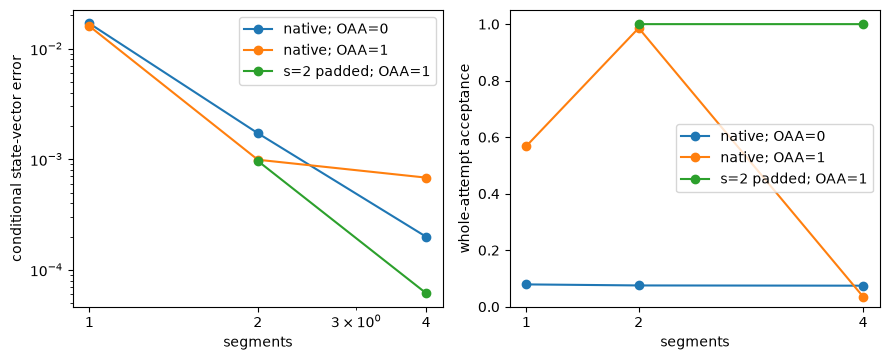

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.7))
for rounds, padded in ((0, False), (1, False), (1, True)):
    subset = [c for c in checks if c["rounds_per_segment"] == rounds and c["normalization2_padding"] == padded]
    label = f"{'s=2 padded' if padded else 'native'}; OAA={rounds}"
    axes[0].loglog([c["segments"] for c in subset], [c["conditional_state_vector_error"] for c in subset], "o-", label=label)
    axes[1].plot([c["segments"] for c in subset], [c["full_attempt_acceptance_probability"] for c in subset], "o-", label=label)
axes[0].set(xlabel="segments", ylabel="conditional state-vector error")
axes[1].set(xlabel="segments", ylabel="whole-attempt acceptance", ylim=(0, 1.05))
for ax in axes:
    ax.set_xticks((1, 2, 4), (1, 2, 4))
    ax.legend()
fig.tight_layout()
display(fig)
plt.close(fig)

## Actual complete-attempt ledger

Every retry resets the basis input. Each segment measures all degree/word/padding flags, resets them before reuse and runs even if an earlier segment failed. Accept only all-zero ancillary outcomes; the final system Z readout retains the output bits. The table counts actual primitive circuits, including preparation, SELECT, uncomputation, forward/inverse OAA accesses, reflections, measurements and reset. Arbitrary rotations remain unsynthesized.

In [5]:
ledger = []
for steps, rounds, padded, access in cases:
    attempt = wt.build_word_attempt(access, steps, rounds, padding_to_two=padded)
    compiled = wt.decompose_word_circuit(attempt)
    counts = compiled.count_ops()
    ledger.append({"segments": steps, "OAA": rounds, "s=2 padded": padded,
                   "qubits": compiled.num_qubits, "CX": counts.get("cx", 0),
                   "arbitrary rotations": sum(counts.get(g, 0) for g in ("rx", "ry", "rz")),
                   "measurements": counts.get("measure", 0), "resets": counts.get("reset", 0),
                   "A/A inverse calls": attempt.metadata["total_A_or_inverse_calls_per_attempt"],
                   "ancilla reflections": attempt.metadata["zero_ancilla_reflections_per_attempt"]})
display(pd.DataFrame(ledger))

,segments,OAA,s=2 padded,qubits,CX,arbitrary rotations,measurements,resets,A/A inverse calls,ancilla reflections
0,1,0,False,10,506,60,10,10,1,0
1,1,1,False,10,1650,231,10,10,3,2
2,2,0,False,10,1012,121,18,18,2,0
3,2,1,False,10,3300,463,18,18,6,4
4,2,1,True,12,4626,486,22,22,6,4
5,4,0,False,10,2024,243,34,34,4,0
6,4,1,False,10,6600,927,34,34,12,8
7,4,1,True,12,9252,972,42,42,12,8


## Source scaling independent of statevector checks

PREPARE loads only $K+1$ degree coefficients and $L$ term coefficients. It builds K independent term circuits. SELECT enumerates $LK(K+1)/2$ active degree-slot-term patterns. The width is $n+\lceil\log_2(K+1)\rceil+K\lceil\log_2L\rceil$, plus two padding flags if selected. The following fixed-K/fixed-step counts have no equal-accuracy claim as n grows.

In [6]:
scaling = []
for n in (1, 2, 3, 4, 6, 8):
    chain_terms = []
    for i in range(n-1):
        label = ["I"]*n
        label[n-1-i] = label[n-2-i] = "Z"
        chain_terms.append((.6, "".join(label)))
    for i in range(n):
        label = ["I"]*n
        label[n-1-i] = "X"
        chain_terms.append((.35, "".join(label)))
    generated = wt.build_word_taylor(chain_terms, .25, 3)
    scaling.append({"n": n, "L": len(chain_terms), "total wires": generated.circuit.num_qubits,
                    "degree-slot-term predicates": generated.circuit.metadata["SELECT_slot_degree_term_predicates"],
                    "source instructions": generated.circuit.size(), "simulation performed": False})
display(pd.DataFrame(scaling))

,n,L,total wires,degree-slot-term predicates,source instructions,simulation performed
0,1,1,3,6,29,False
1,2,3,10,18,155,False
2,3,5,14,30,329,False
3,4,7,15,42,431,False
4,6,11,20,66,863,False
5,8,15,22,90,1079,False


The native four-segment circuit has smaller truncation error than its one-round OAA variant, which overshoots. Normalization2 padding supplies a distinct checked variant and improves that example's acceptance and distortion; it does not certify deterministic evolution. The artifact ledger records acceptance-sensitive hypothetical synthesis and accepted-shot budgets. Finite-shot sampling, physical timing/error correction and formal proof remain unavailable.

The optional control below needs a live kernel. Static execution suppresses widget objects.

In [7]:
if os.environ.get("OPENQUANTUM_STATIC_BUILD") != "1":
    import ipywidgets as widgets
    def explore(segments=4, padded=True):
        access = wt.build_word_taylor(terms, 1/segments, 3)
        if padded and access.normalization > 2:
            return "Normalization2 padding requires more segments so native s<=2."
        result = wt.compare_word_dynamics(access, segments, 1, padding_to_two=padded)
        return {key: result[key] for key in ("conditional_state_vector_error", "observable_error", "full_attempt_acceptance_probability")}
    display(widgets.interactive(explore, segments=widgets.IntSlider(value=4, min=1, max=4, step=1), padded=True))